In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

# Generate synthetic data with a linear relationship and random noise
X = np.linspace(0, 10, 200).reshape(-1, 1)
y = 4 * X.ravel() + 7 + np.random.normal(0, 3, size=200)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160
Testing samples: 40


In [2]:
# Add an intercept column to the training design matrix
X_train_design = np.c_[
    np.ones(X_train.shape[0]), X_train
]

# Estimate model coefficients using the pseudoinverse
theta = np.linalg.pinv(X_train_design) @ y_train

# Generate predictions for the training and test sets
X_test_design = np.c_[
    np.ones(X_test.shape[0]), X_test
]

y_train_pred = X_train_design @ theta
y_test_pred = X_test_design @ theta

print("Intercept:", round(theta[0], 4))
print("Slope:", round(theta[1], 4))

Intercept: 6.5591
Slope: 4.0506


In [3]:
# Calculate evaluation metrics on unseen test data
mse_scratch = mean_squared_error(y_test, y_test_pred)
rmse_scratch = np.sqrt(mse_scratch)
r2_scratch = r2_score(y_test, y_test_pred)

print("Test MSE:", round(mse_scratch, 4))
print("Test RMSE:", round(rmse_scratch, 4))
print("Test R²:", round(r2_scratch, 4))

Test MSE: 6.9472
Test RMSE: 2.6358
Test R²: 0.9433


In [4]:
# Train a scikit-learn linear regression model
sklearn_model = LinearRegression()
sklearn_model.fit(X_train, y_train)

# Predict test values using scikit-learn
y_test_pred_sklearn = sklearn_model.predict(X_test)

# Calculate evaluation metrics
mse_sklearn = mean_squared_error(y_test, y_test_pred_sklearn)
rmse_sklearn = np.sqrt(mse_sklearn)
r2_sklearn = r2_score(y_test, y_test_pred_sklearn)

# Compare both implementations
comparison = pd.DataFrame({
    "Model": ["From Scratch", "scikit-learn"],
    "MSE": [mse_scratch, mse_sklearn],
    "RMSE": [rmse_scratch, rmse_sklearn],
    "R²": [r2_scratch, r2_sklearn]
})

comparison.round(4)

,Model,MSE,RMSE,R²
0,From Scratch,6.9472,2.6358,0.9433
1,scikit-learn,6.9472,2.6358,0.9433


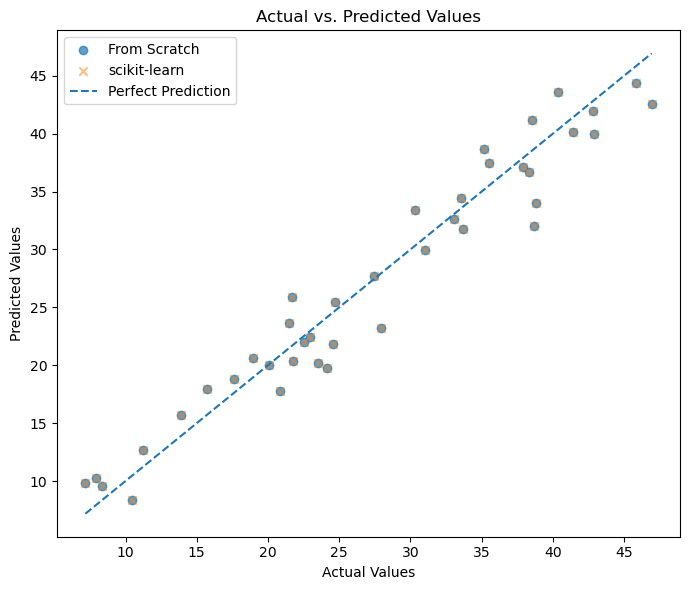

In [5]:
# Compare actual and predicted values on the test set
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test, y_test_pred,
    alpha=0.7,
    label="From Scratch"
)

plt.scatter(
    y_test, y_test_pred_sklearn,
    alpha=0.5,
    marker="x",
    label="scikit-learn"
)

# Add a reference line for perfect predictions
lower = min(y_test.min(), y_test_pred.min(), y_test_pred_sklearn.min())
upper = max(y_test.max(), y_test_pred.max(), y_test_pred_sklearn.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.tight_layout()

# Save the prediction comparison plot
plt.savefig(
    "../reports/figures/model_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

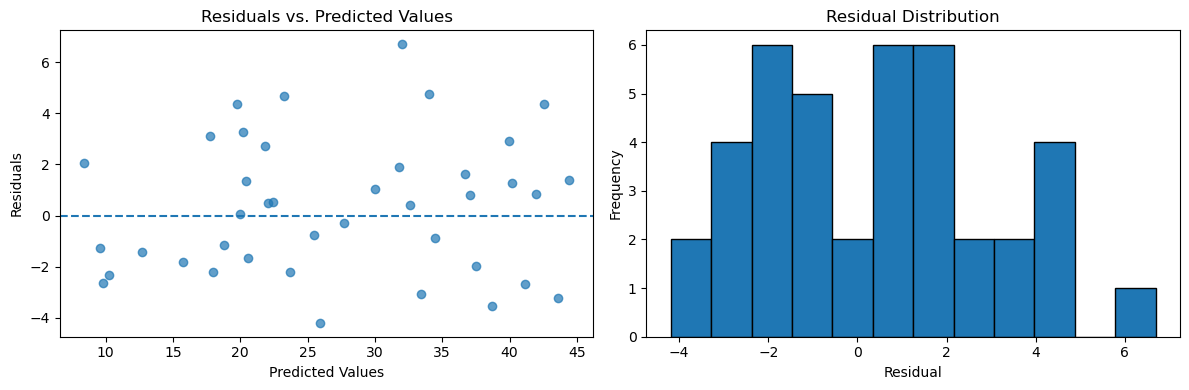

In [6]:
# Calculate prediction residuals on the test set
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot residuals against predicted values
axes[0].scatter(y_test_pred, residuals, alpha=0.7)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Predicted Values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs. Predicted Values")

# Examine the distribution of residuals
axes[1].hist(residuals, bins=12, edgecolor="black")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Residual Distribution")

plt.tight_layout()

# Save the residual analysis plot
plt.savefig(
    "../reports/figures/model_residual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
# Save the model evaluation metrics
comparison.to_csv(
    "../reports/model_evaluation.csv",
    index=False
)

# Save actual values, predictions, and residuals
prediction_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted From Scratch": y_test_pred,
    "Predicted scikit-learn": y_test_pred_sklearn,
    "Residual": residuals
})

prediction_results.to_csv(
    "../reports/model_predictions.csv",
    index=False
)

print("Model evaluation results saved successfully.")

comparison.round(4)

Model evaluation results saved successfully.


,Model,MSE,RMSE,R²
0,From Scratch,6.9472,2.6358,0.9433
1,scikit-learn,6.9472,2.6358,0.9433
